**This problem set is due Wednesday, November 4, 2026 at 11:59 pm. Please plan ahead and submit your work on time.**

# Problem Set 07: Reinforcement Learning

In this problem set, you will implement model-free approaches for reinforcement learning.


0. [Credit for Contributors (required)](#contributors)

1. [Passive Reinforcement Learning (50 points)](#problem1)
    1. [Direct Evaluation (15 points)](#direct_evaluation)
    2. [Sample Sensitivity (10 points)](#sample_sensitivity)
    3. [Temporal Difference Learning (15 points)](#temporal_difference)
    4. [Learning Rate Sensitivity (10 points)](#learning_rate)
2. [Active Reinforcement Learning (35 points)](#problem2)
    1. [Q-Learning (15 points)](#Qlearning)
    2. [Epsilon-Greedy Q-Learning (10 points)](#epsilon_greedy)
    3. [Exploration vs. Exploitation (10 points)](#exploration)
3. [Exploration Functions vs. Epsilon-Greedy [AI-enabled] (10 points)](#problem3)
    1. [An MDP Where Exploration Functions Win [AI-enabled] (5 points)](#exploration_mdp)
    2. [Visualizing Why Exploration Functions Win [AI-enabled] (5 points)](#exploration_visualization)
4. [Time Spent on Pset (5 points)](#part4)
    
**100 points** total for Problem Set 7

## Imports and Utilities

In [1]:
# Be sure to run the cell below to import the code needed for this assignment.
from __future__ import division

%matplotlib inline
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import copy
import networkx as nx
from grid import MDPGrid, generate_mdp_plot, generate_grid_plot
from mdp_utils import *

# imports for autograder
from principles_of_autonomy.grader import Grader
from principles_of_autonomy.notebook_tests.pset_7 import TestPSet7

## <a name="contributors"></a> Credit for Contributors

List the various students, lecture notes, or online resouces that helped you complete this problem set:

Ex: I worked with Bob on the cat reinforcement learning problem.

<div class="alert alert-info">
Write your answer in the cell below this one.
</div>

Lecture 13, 14 slides.


## <a name="problem1"></a> 1: Passive Reinforcement Learning (50 points)

In this problem, you will implement the Passive Reinforcement Learning approaches we saw in class: Direct Evaluation and Temporal Difference Learning.

The problems in this problem set are based on the simple MDP class from Problem Set 6 defined in the `mdp_utils.py` file. Feel free to open Problem Set 6 for a reminder of the MDP definition and the grid world our robot operates in. This week, however, we assume that we don't know the transition function T or the reward function R. Instead, we will implement model-free reinforcement learning methods to calculate the Values and/or Q-Values.

We provide you with a `generate_episodes` function that generates episodes from an agent acting according to a policy in the MDP:

```python
def generate_episodes(mdp, policy, num_episodes=5, max_steps=15)
```

Let's build the simple MDP from last week and visualize it again:

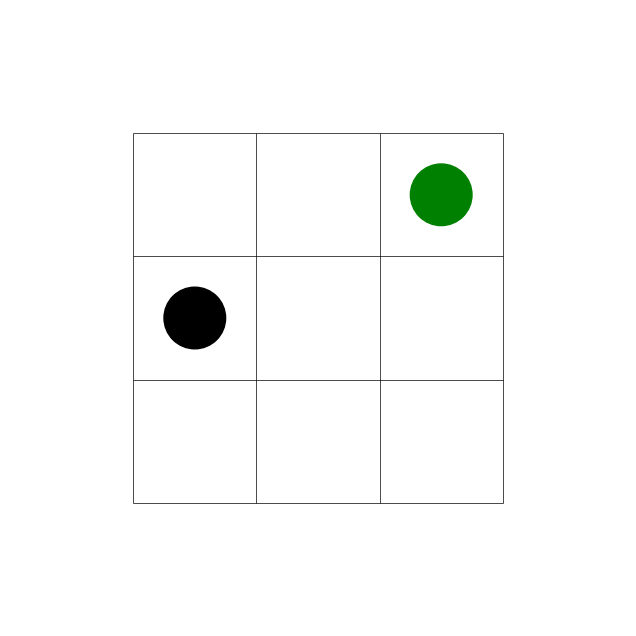

In [2]:
n = 3
goal = (2, 2)
obstacles = [(0, 1)]

# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

# Visualize the MDP:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Draw goal and obstacle cells.
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')

Now let's create a policy to follow when we generate episodes:

In [3]:
# Create simple policy that always moves right.
policy = {s: 'right' for s in mdp.S}

Now let's generate some episodes according to this policy in the MDP:

In [4]:
episodes = generate_episodes(mdp, policy, num_episodes=10, max_steps=100)

Run the following print block to look at the generated episodes. Notice how they have different lengths because they reach terminal states at different times. Notice also how the stochasticity of the MDP manifests itself in the samples of an episode: sometimes you take an action and end up where you intended; other times the action takes you in a different state. The ratio of these outcomes is implicit from the transition probabilities of the environment.

In [5]:
# Each episode is a list of (state, action, state', reward) tuples
for i, episode in enumerate(episodes):
    print(f"Episode {i+1} of length {len(episode)}: ".format(i, episode), episode, "\n")

Episode 1 of length 22:  [((1, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 1), 0.0), ((2, 1), 'right', (2, 2), 100)] 

Episode 2 of length 2:  [((0, 2), 'right', (1, 2), 0.0), ((1, 2), 'right', (2, 2), 100)] 

Episode 3 of length 21:  [((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0), 0.0), ((2, 0), 'right', (2, 0

### <a name="direct_evaluation"></a> 1A. Direct Evaluation (15 points)

In this part of the problem, you will implement **Direct Evaluation** (also called Monte-Carlo Evaluation). Your function should have the following signature:
```python
def direct_evaluation(episodes: list, gamma: float) -> dict
```

The function takes in a list of episodes representing different experiences of the agent acting according to a fixed policy in the MDP, and the discount factor gamma. The function should return a Python dictionary with the estimated value for each state in the MDP.

In general Direct Evaluation has 2 variants: First-Visit and Every-Visit. In First-Visit, we only add a sample of discounted rewards to the value estimate whenever we encounter a state for the first time in the episode. In Every-Visit, we add a sample *every* time we encounter a state (even if it's repeated). You should implement the First-Visit variant of Direct Evaluation that we talked about in class. For this, you'll find it useful to keep track of states visited so far in the episode with a `visited_states` list (that you reset whenever you move on to the next episode).

<div class="alert alert-info">
Implement the function `direct_evaluation(episodes, gamma)` below.
</div>

In [6]:
from collections import defaultdict

In [7]:
def direct_evaluation(episodes: list, gamma: float) -> dict:
    """
    Direct Evaluation method to estimate the value function for each state for a fixed policy.
    
    Args:
        episodes (list): A list of episodes. Each episode is a list of (state, action, state', reward) tuples.
        gamma (float): The discount factor.
        
    Returns:
        V: A dictionary mapping states to their estimated value V(s).
    """
    value_dict = defaultdict(list)
    for episode in episodes:
        visited_states = set()
        for index in range(len(episode)):
            if episode[index][0] in visited_states:
                continue
            visited_states.add(episode[index][0])
            
            updated_value = episode[index][3]
            discount = gamma
            for state in episode[index + 1:]:
                updated_value += discount * state[3]
                discount = discount * gamma
            value_dict[episode[index][0]].append(updated_value)

    averages = {}
    for value in value_dict:
        averages[value] = sum(value_dict[value]) / len(value_dict[value])
            
    
    return averages

Check out how your code performs on the initial grid world we defined:

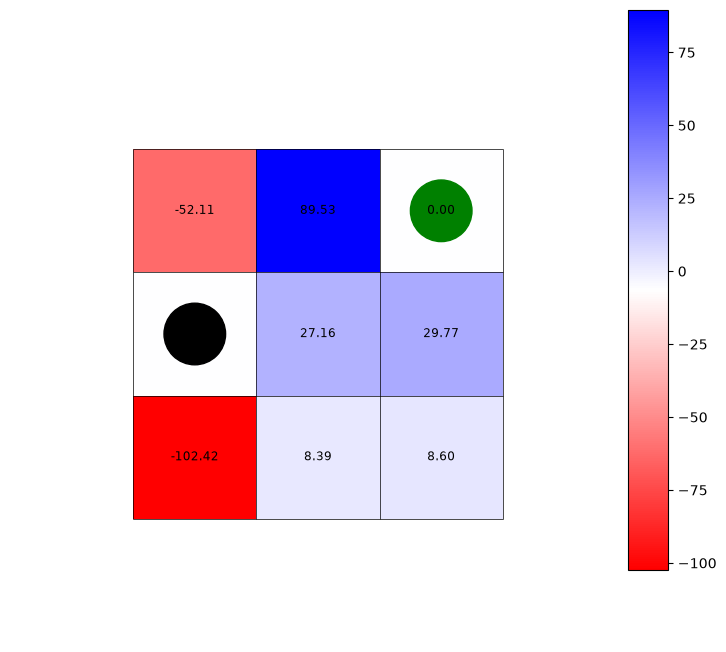

In [8]:
# Test your code for direct evaluation with the example from before and a policy that always goes right.

# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
n = 3
goal = (2, 2)
obstacles = [(0, 1)]
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

# Create simple policy that always moves right.
policy = {s: 'right' for s in mdp.S}

# Generate some episodes.
episodes = generate_episodes(mdp, policy, num_episodes=100000, max_steps=100)

# Perform direct evaluation with these episodes.
V = direct_evaluation(episodes, mdp.gamma)

# Visualize values:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot values with colors and numbers.
g.plot_V(axes, V, print_numbers=True)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')

You can convince yourself this is correct by running Policy Evaluation in the PSet 6 notebook with this always-go-right policy and comparing the values.

In [9]:
"""Test your direct evaluation code here."""
Grader.run_single_test_inline(TestPSet7, "test_1_direct_evaluation", locals())

Test passed!!

.
----------------------------------------------------------------------
Ran 1 test in 1.374s

OK


### <a name="sample_sensitivity"></a> 1B. Sample Sensitivity (10 points)

In class, we discussed that Direct Evaluation, while simple, has a number of limitations. We now want to observe its performance with varying sample sizes. Run the MDP example above with a varying number of samples; concretely, run the block with different values for `num_episodes` inside `generate_episodes`. Try 100, 1000, 10000, and 100000. For each `num_episodes` value run the block a few times, then answer the following:

1. What trends do you observe in the value estimates as you increase the number of episodes?
2. How does the number of samples affect the convergence of the value function?
3. Why does Direct Evaluation require a large number of samples to provide accurate estimates?


<div class="alert alert-info">
Write your answer in the cell below this one.
</div>

In [19]:

for episode_number in [100, 1000, 10000, 100000]:
    episodes = generate_episodes(mdp, policy, num_episodes=episode_number, max_steps=100)
    print(f"Results with {episode_number} episodes:")
    V =  direct_evaluation(episodes, mdp.gamma)
    print_strings = sorted([f"{value}: {V[value]}" for value in V])
    for s in print_strings:
        print(s)
    print("----")


Results with 100 episodes:
(0, 0): -74.98738516125933
(0, 1): 0.0
(0, 2): -67.935232
(1, 0): 8.433611252745399
(1, 1): 35.94028349189697
(1, 2): 95.2877037037037
(2, 0): 7.003681743814218
(2, 1): 37.872907734508004
(2, 2): 0.0
----
Results with 1000 episodes:
(0, 0): -104.17221330774784
(0, 1): 0.0
(0, 2): -40.54055816261866
(1, 0): 8.884040915959899
(1, 1): 24.74753988077898
(1, 2): 89.64299628626502
(2, 0): 9.326273389160649
(2, 1): 30.55672400947122
(2, 2): 0.0
----
Results with 10000 episodes:
(0, 0): -91.18950150628983
(0, 1): 0.0
(0, 2): -28.81616867413882
(1, 0): 8.152846469622588
(1, 1): 26.592559250632732
(1, 2): 89.60605085198165
(2, 0): 8.245906644431704
(2, 1): 29.869315138183786
(2, 2): 0.0
----
Results with 100000 episodes:
(0, 0): -102.97880897374753
(0, 1): 0.0
(0, 2): -47.543887101044945
(1, 0): 8.245201945262025
(1, 1): 27.15936819094814
(1, 2): 89.15304402036502
(2, 0): 8.41709699286804
(2, 1): 30.01821446873997
(2, 2): 0.0
----


#### What trends do you observe in the value estimates as you increase the number of episodes?

As the number of episodes increase, the change in the value estimates decrease over time. This means they converge to stable values.

#### How does the number of samples affect the convergence of the value function?
The impact of 10x the number of samples starts to diminish, but it only really stabilizes around 1000 episodes. After that, we get very small adjustments.

#### Why does Direct Evaluation require a large number of samples to provide accurate estimates?
Direct evaluation does not make any modeling assumptions about transitions or action states, and is working with much less meaningful data. As a result though, it is more reusable in a variety of contexts regardless of the complexity of the modeled problem.


### <a name="temporal_difference"></a> 1C. Temporal Difference Learning (15 points)

In this part of the problem, you will implement **Temporal Difference Learning**, which loops over the episode samples and performs the TD update to the value function one sample at a time. Your function should have the following signature:
```python
def td_learning(episodes: list, gamma: float, alpha: float) -> dict
```

The function takes in a list of episodes experienced by following the fixed policy in the MDP, the discount factor gamma, and the learning rate alpha for blending past values with the new sample. The function should return a Python dictionary with the estimated value for each state in the MDP.

<div class="alert alert-info">
Implement the function `td_learning(episodes, gamma, alpha)` below.
</div>

In [15]:
def td_learning(episodes: list, gamma: float, alpha: float) -> dict:
    """
    Temporal-Difference Learning to estimate the value function for a fixed policy.
    
    Args:
        episodes (list): A list of episodes. Each episode is a list of (state, action, state', reward) tuples.
        gamma (float): The discount factor of the MDP.
        alpha (float): The learning rate.
        
    Returns:
        V: A dictionary mapping states to their estimated value V(s).
    """
    values = defaultdict(int)

    for episode in episodes:
        for transition in episode:
            state, action, next_state, next_reward = transition
            target = next_reward + gamma * values[next_state]
            values[state] = values[state] + alpha * (target - values[state])
    return values

Check out how your code performs on the initial grid world we defined:

In [16]:
# Test your code for TD Learning with the example from before and a policy that always goes right.

# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
n = 3
goal = (2, 2)
obstacles = [(0, 1)]
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

# Create simple policy that always moves right.
policy = {s: 'right' for s in mdp.S}

# Generate some episodes.
episodes = generate_episodes(mdp, policy, num_episodes=100000, max_steps=100)

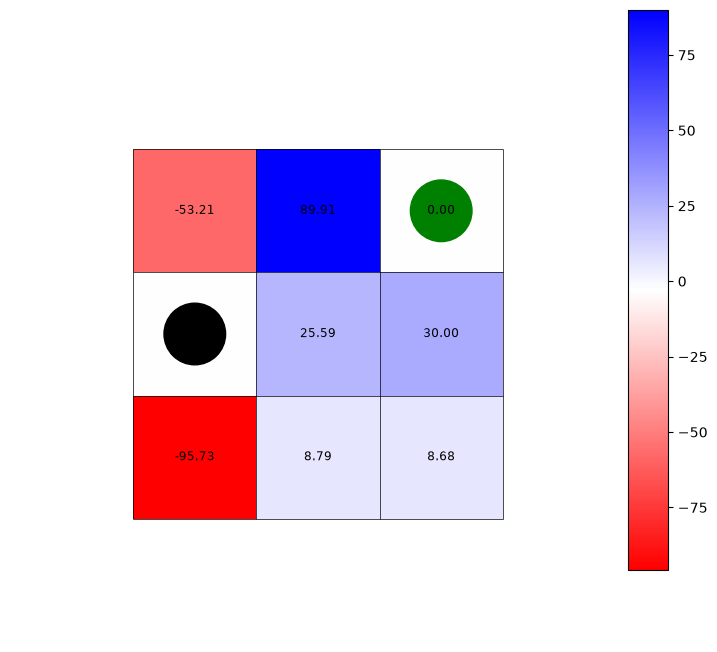

In [17]:
# Perform TD learning with these episodes.
alpha = 0.01
V = td_learning(episodes, mdp.gamma, alpha)

# Visualize values:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot values with colors and numbers.
g.plot_V(axes, V, print_numbers=True)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')

In [18]:
"""Test your TD learning code here."""
Grader.run_single_test_inline(TestPSet7, "test_2_TD_learning", locals())

Test passed!!

.
----------------------------------------------------------------------
Ran 1 test in 1.311s

OK


### <a name="learning_rate"></a> 1D. Learning Rate Sensitivity (10 points)

In the code above, we ran TD Learning with alpha = 0.01. Try experimenting with more values of alpha: 0.00001, 0.0001, 0.001, 0.01, 0.1, 0.5. Answer the following based on what you observe:

1. How does a very low learning rate (e.g., alpha = 0.00001) affect the value function compared to a moderate learning rate (e.g., alpha = 0.01)? What about a very high learning rate (e.g., alpha = 0.5)?
2. Identify a learning rate that seems to work well for your specific MDP setup and explain why you think it strikes the right balance.
3. Reflecting on your results, how do you think the choice of learning rate might affect the performance of TD Learning in more complex environments?

<div class="alert alert-info">
Write your answer in the cell below this one.
</div>

In [20]:

for alpha in [0.00001, 0.0001, 0.001, 0.1, 0.5]:
    episodes = generate_episodes(mdp, policy, num_episodes=100000, max_steps=100)
    print(f"Results with {alpha} alpha:")
    V =  td_learning(episodes, mdp.gamma, alpha)
    print_strings = sorted([f"{value}: {V[value]}" for value in V])
    for s in print_strings:
        print(s)
    print("----")


Results with 1e-05 alpha:
(0, 0): -11.20579321501987
(0, 1): 0.0
(0, 2): -10.604492059644059
(1, 0): 0.36694860243090244
(1, 1): 1.6320167875055251
(1, 2): 17.85413851842858
(2, 0): 5.077634436532116
(2, 1): 24.46004057037794
(2, 2): 0.0
----
Results with 0.0001 alpha:
(0, 0): -68.83463122785894
(0, 1): 0.0
(0, 2): -41.584301780618894
(1, 0): 6.263014944339362
(1, 1): 19.012589223182953
(1, 2): 79.90523301484012
(2, 0): 8.583218157225042
(2, 1): 29.683428205057343
(2, 2): 0.0
----
Results with 0.001 alpha:
(0, 0): -107.72593649283746
(0, 1): 0.0
(0, 2): -52.880180856613514
(1, 0): 8.177107225663
(1, 1): 27.29542807647744
(1, 2): 89.00868522434226
(2, 0): 8.762740931021368
(2, 1): 29.98135869846587
(2, 2): 0.0
----
Results with 0.1 alpha:
(0, 0): -189.76291235681936
(0, 1): 0.0
(0, 2): -47.95681971505083
(1, 0): 11.547863036976127
(1, 1): 35.12149794299845
(1, 2): 89.10610325772225
(2, 0): 9.934780925248628
(2, 1): 34.36479939852511
(2, 2): 0.0
----
Results with 0.5 alpha:
(0, 0): -254.

#### How does a very low learning rate (e.g., alpha = 0.00001) affect the value function compared to a moderate learning rate (e.g., alpha = 0.01)? What about a very high learning rate (e.g., alpha = 0.5)?

Very low learning rates result in not enough progress being made with reasonable numbers of episodes to get to steady state values. Medium learning rates make good use of the data, but very high learning rates tend to overshoot and get to totally incorrect values.

#### Identify a learning rate that seems to work well for your specific MDP setup and explain why you think it strikes the right balance.

0.001 seems to work best, getting us close to the values obtained for very high episodes in 1B. Higher numbers tend to overshoot, and lower numbers do not quite reach the steady state values.

#### Reflecting on your results, how do you think the choice of learning rate might affect the performance of TD Learning in more complex environments?

We should use lower learning rates in data rich environments and faster ones in data poor ones. However, there is also a need to have a sufficient amount of data relative to the environments complexity, so learning rate alone is insufficient.

## <a name="problem2"></a> 2: Active Reinforcement Learning (35 points)

Passive Reinforcement Learning is useful for evaluating fixed policies without explicit knowledge of T and R. However, it can't be used for turning these values into a new (improved) policy. For that, we need active interactions with the environment (not just passive reflection on past episodes). In this problem, we switch over to Active Reinforcement Learning, specifically to Q-Learning, and we will investigate the exploration-exploitation tradeoff and how that can affect the algorithm's efficiency.

Since we are interacting with the world in real time now, instead of using `generate_episodes` to generate experiences to learn from, we will use a function `sample_environment` which given a state and an action it queries the MDP environment for the resulting next state and reward:

```python
def sample_environment(mdp: MDP, state: tuple, action: str) -> tuple[tuple, float]
```

You can try running the following block to see how to call `sample_environment` and what it returns. Try running it a few times (and possibly with different states and actions) to convince yourself that there is stochasticity involved. (Note if you runt the following cell after running code for Q-learning below you may find that it's no longer stochastic because we set a random seed in that part for grading.)

In [25]:
# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
n = 3
goal = (2, 2)
obstacles = [(0, 1)]
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

state = (1, 2)
action = "right"
next_state, reward = sample_environment(mdp, state, action
                                       )
print(state, action, next_state, reward)

(1, 2) right (1, 2) 0.0


Before we dive into implementing Q-Learning, let's first see some Q-values. We will store Q-values as a Python dictionary that maps each state in the MDP to another dictionary that maps each action to the corresponding Q-value. To see an example, here's what a random Q-Value function looks like:

In [26]:
# A random Q-value function:
def random_Q(states: list[tuple], actions: list[str]):
    # Initialize empty Q-values dictionary.
    Q = {}
    # Generate random Q-values between minV and maxV.
    minQ, maxQ = -100, 100
    for state in states:
        Q[state] = {}
        for action in actions:
            Q[state][action] = np.random.uniform(minQ, maxQ)
    return Q

# Print values generated with the random Q-Value function.
print("Q_random is a valid Q-Value function, although definitely not optimal (it's just random!)")
n = 3
mdp = build_mdp(n, 0.8, [], (1, 1), 0.8)
Q_random = random_Q(mdp.S, mdp.A)
Q_random

Q_random is a valid Q-Value function, although definitely not optimal (it's just random!)


{(0, 1): {'up': 37.76343177090615,
  'down': 60.553397055511084,
  'right': -19.197044138896004,
  'left': 95.01721777323536},
 (1, 2): {'up': -85.69193686585797,
  'down': 72.68064376407995,
  'right': 15.166419198278792,
  'left': -5.050278979254275},
 (2, 1): {'up': -41.228739149044216,
  'down': -49.44157344173203,
  'right': -35.91059401074026,
  'left': -85.77428183406575},
 (0, 0): {'up': -97.95788219185467,
  'down': 75.8913855724767,
  'right': 38.82473221417029,
  'left': -18.35263842995709},
 (1, 1): {'up': 81.8724750923974,
  'down': 35.2847102300401,
  'right': 13.345230976782418,
  'left': 54.211832620919196},
 (2, 0): {'up': 32.43410786554104,
  'down': 91.13083421298694,
  'right': -47.868818419516245,
  'left': 11.780070227462435},
 (0, 2): {'up': -16.153786592061547,
  'down': 91.64174523782252,
  'right': 34.32602049972131,
  'left': -91.51037047952013},
 (2, 2): {'up': -86.5790840913252,
  'down': -74.34859709964448,
  'right': 34.429644487443234,
  'left': -34.2046

Let's now visualize these Q-values in the grid:

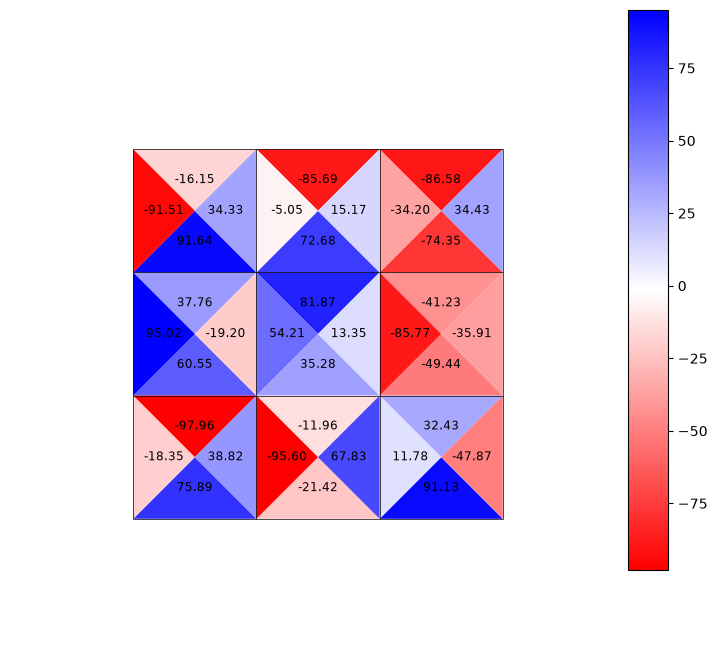

In [27]:
# Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()

# Plot Q in the grid.
g.plot_Q(axes, Q_random, print_numbers = True)

### <a name="Qlearning"></a> 2A. Q-Learning (15 points)

You will now implement **Q-Learning**. While Direct Evaluation and TD Learning were on-policy (they relied on samples coming from a fixed policy), Q-Learning is off-policy (doesn't depend on samples from one fixed policy), can choose its own actions as we go, and can converge to the optimal policy even if the agent is acting suboptimally. You should thus make use of `sample_environment` in your code to try out actions in the environment. For this problem, you should use a random action selection strategy meaning you should choose randomly from the available actions to sample the environment.

Your function should have the following signature:
```python
def q_learning(num_episodes: int, mdp: MDP, gamma: float, alpha: float, max_steps: int = 100)
```

The function takes in the number of episodes your agent can attempt in the MDP, the discount factor gamma, the learning rate alpha (similar to TD learning), and a maximum length for each episode (to avoid infinite episodes). The function should return a Python dictionary with the estimated Q-value for each (state, action) pair in the MDP, as well as a policy that results from maximizing the final values at each state.

To help you out, we provide some starter code that initializes an empty Q-value dictionary, loops through episodes, and starts an episode at a random state. The function `mdp.is_sink_state(state)` checks whether a state is terminal or not; the episode ends right after we enter a terminal state or when we reach the maximum allowable length of the episode max_steps.

<div class="alert alert-info">
Implement the function `q_learning(num_episodes, gamma, alpha, max_steps=100)` below.

Complete the two To dos.
</div>

In [33]:
def q_learning(num_episodes: int, mdp: MDP, gamma: float, alpha: float, max_steps: int = 100):
    """
    Active Q-Learning with random action selection.
    
    Args:
        num_episodes (int): The number of episodes to run.
        gamma (float): The discount factor of the MDP.
        alpha (float): The learning rate.
        max_steps (int): The maximum number of steps per episode to avoid infinite loops.
        
    Returns:
        Q: A dictionary mapping states to another dictionary mapping actions to their estimated Q-values.
        policy: A dictionary mapping states to actions to take.
    """
    # in real life, you won't have access to mdp. We are including it as a parameter for testing purposes.
    # DO NOT USE mdp.R or mdp.T!

    # Initialize Q-value dictionary.
    Q = {state: {action: 0.0 for action in mdp.A} for state in mdp.S}
    
    # Loop through episodes.
    for episode in range(num_episodes):
        # Start episode in a random state.
        state = random.choice(list(mdp.S))
        # Track number of steps in episode.
        steps = 0
        # While the episode is not done.
        while not mdp.is_sink_state(state) and steps < max_steps:
            steps += 1

            # Pick an action randomly
            action = random.choice(mdp.A)

            ### TO DO 1: sample the environment, update Q-values using the Q-learning update rule, and transition to the next state.
            next_state, reward = sample_environment(mdp, state, action)
            target = reward + gamma * max(Q[next_state].values())
            Q[state][action] = Q[state][action] + alpha * (target - Q[state][action])
            state = next_state
            

    ### TO DO 2: Derive policy from Q-values by maximizing over actions at each state.
    policy = {}
    for state in Q:
        best_action = None
        for action in Q[state]:
            if best_action is None or Q[state][best_action] < Q[state][action]:
                best_action = action
        policy[state] = best_action
    
    return Q, policy

Check out how your code performs on the initial grid world we defined:

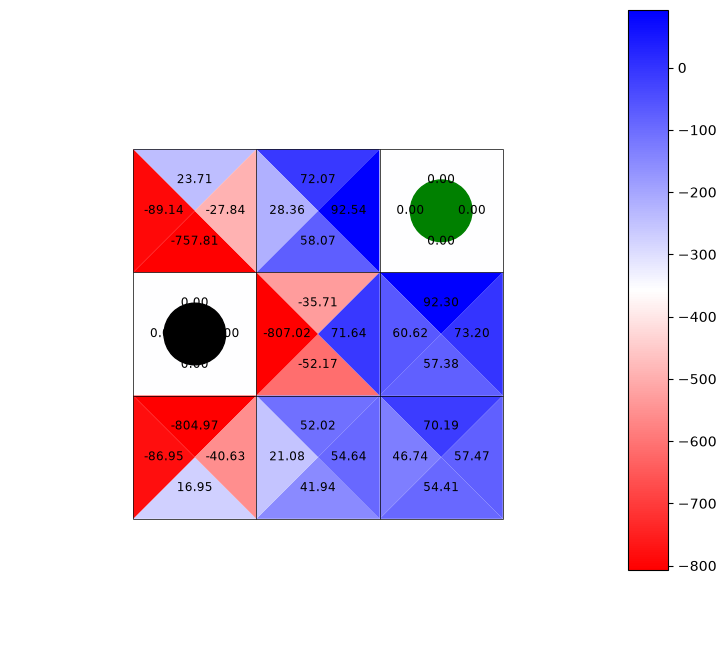

In [114]:
# Test your code for Q Learning with the example from before.

# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
n = 3
goal = (2, 2)
obstacles = [(0, 1)]
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

# Perform Q learning with these episodes.
alpha = 0.01
num_episodes = 10000
Q, policy = q_learning(num_episodes, mdp, mdp.gamma, alpha)

# Visualize values:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot values with colors and numbers.
g.plot_Q(axes, Q, print_numbers=True)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')   

Convince yourself that the optimal policy is the same one we got with Policy Extraction when we knew the ground truth T and R values in Problem Set 4.

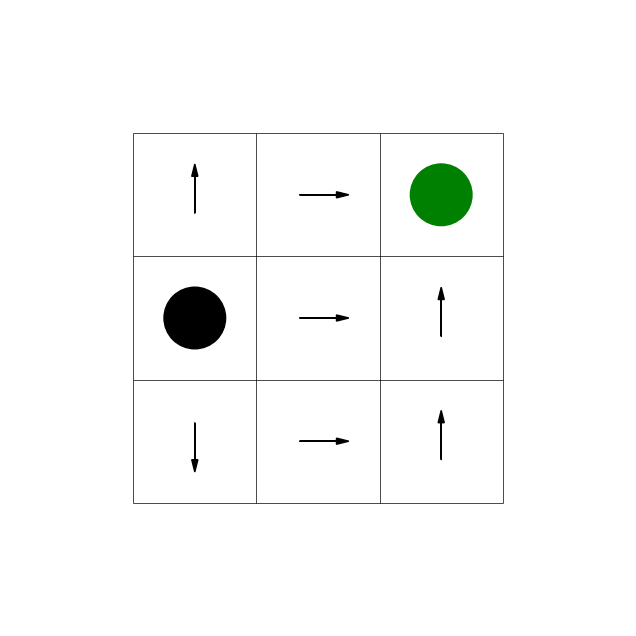

In [115]:
# Visualize the result.
# 1. Create grid for plotting
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot the values and the policy.
g.plot_policy(axes, policy)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k') 

In [116]:
"""Test your Q learning code here."""
Grader.run_single_test_inline(TestPSet7, "test_3_Q_learning", locals())

Test passed!!

.
----------------------------------------------------------------------
Ran 1 test in 0.096s

OK


### <a name="epsilon_greedy"></a> 2B. Epsilon-Greedy Q-Learning (10 points)

We saw in class that an agent that selects actions randomly will take longer to explore the space and converge than one that has a more clever exploration strategy. We will now implement an **Epsilon-Greedy** variant of Q-Learning, meaning it chooses random actions an epsilon fraction of the time, and follows its current best Q-values otherwise. Note that choosing a random action may result in choosing the best action - that is, you should not choose a random sub-optimal action, but rather any random legal action.

Your function should have the following signature:
```python
def q_learning_epsilon_greedy(num_episodes: int, mdp: MDP, gamma: float, alpha: float, epsilon: float, max_steps: int = 100) -> dict
```

The function takes in the number of episodes your agent can attempt in the MDP, the discount factor gamma, the learning rate alpha, the epsilon exploration probability, and the maximum steps of an episode. The function should return a Python dictionary with the estimated Q-value for each state-action pair in the MDP, as well as a policy that results from maximizing the final values at each state.

A good place to start is to just copy your code for `q_learning` below. 

**Important Notes**

It's important to do the following for passing the test.
- Please use `action = random.choice(mdp.A)` to generate the action for each step as we provided above in q-learning. 
- For the **Epsilon-Greedy**  part, please use `if random.uniform(0, 1) < epsilon:` then choose random action otherwise act on current policy.
- You only need < 5 lines of change to your code.

<div class="alert alert-info">
Implement the function `q_learning_epsilon_greedy(num_episodes, gamma, alpha, epsilon, max_steps=100)` below.
</div>

In [117]:
def q_learning_epsilon_greedy(num_episodes: int, mdp: MDP, gamma: float, alpha: float, epsilon: float, max_steps: int = 100) -> dict:
    """
    Active Q-Learning with epsilon-greedy action selection.
    
    Args:
        num_episodes (int): The number of episodes to run.
        gamma (float): The discount factor.
        alpha (float): The learning rate.
        epsilon (float): Exploration probability.
        max_steps (int): The maximum number of steps per episode.
        
    Returns:
        Q: A dictionary mapping states to another dictionary mapping actions to their estimated Q-values.
        policy: A dictionary mapping states to the optimal actions.
    """
    # in real life, you won't have access to mdp. We are including it as a parameter for testing purposes.
    # BEGIN HERE!
    # Initialize Q-value dictionary.
    Q = {state: {action: 0.0 for action in mdp.A} for state in mdp.S}
    
    # Loop through episodes.
    for episode in range(num_episodes):
        # Start episode in a random state.
        state = random.choice(list(mdp.S))
        # Track number of steps in episode.
        steps = 0
        # While the episode is not done.
        while not mdp.is_sink_state(state) and steps < max_steps:
            steps += 1

            if random.uniform(0, 1) < epsilon:
                action = random.choice(mdp.A)
            else:
                action = max(mdp.A, key=lambda a: Q[state][a])
                

            ### TO DO 1: sample the environment, update Q-values using the Q-learning update rule, and transition to the next state.
            next_state, reward = sample_environment(mdp, state, action)
            target = reward + gamma * max(Q[next_state].values())
            Q[state][action] = Q[state][action] + alpha * (target - Q[state][action])
            state = next_state
            

    ### TO DO 2: Derive policy from Q-values by maximizing over actions at each state.
    policy = {}
    for state in Q:
        best_action = None
        for action in Q[state]:
            if best_action is None or Q[state][best_action] < Q[state][action]:
                best_action = action
        policy[state] = best_action
    
    return Q, policy


Check out how your code performs on the initial grid world we defined:

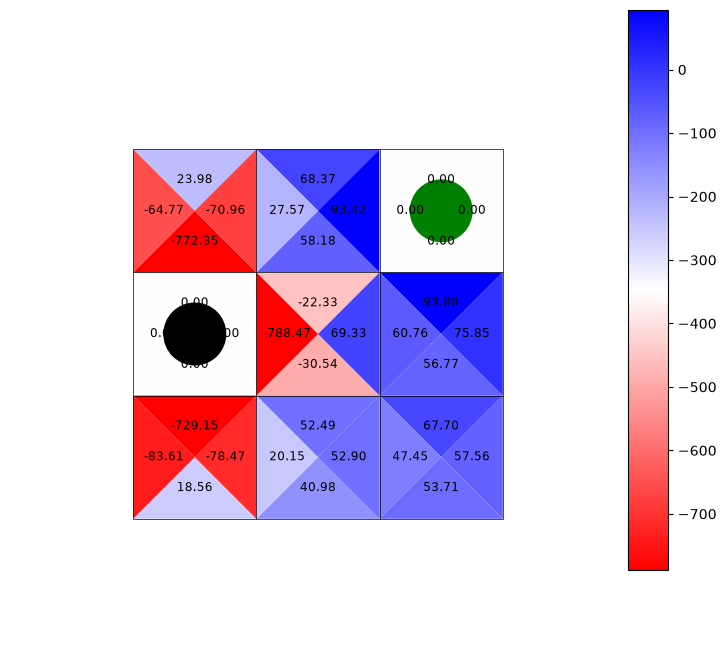

In [118]:
# Test your code for Epsilon Greedy Q Learning with the example from before.

# Build MDP with p=0.8 and gamma=0.8. Use default rewards.
n = 3
goal = (2, 2)
obstacles = [(0, 1)]
mdp = build_mdp(n, 0.8, obstacles, goal, 0.8)

# Perform Q learning with these episodes.
alpha = 0.01
epsilon = 0.5
num_episodes = 10000
Q, policy = q_learning_epsilon_greedy(num_episodes, mdp, mdp.gamma, alpha, epsilon)

# Visualize values:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot values with colors and numbers.

g.plot_Q(axes, Q, print_numbers=True)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')   

In [119]:
"""Test your Epsilon Greedy Q learning code here."""
Grader.run_single_test_inline(TestPSet7, "test_4_Q_learning", locals())

Test passed!!

.
----------------------------------------------------------------------
Ran 1 test in 0.061s

OK


### <a name="exploration"></a> 2C. Exploration vs. Exploitation (10 points)

We will now run your code on the larger grid world with more obstacles. Execute the following code:


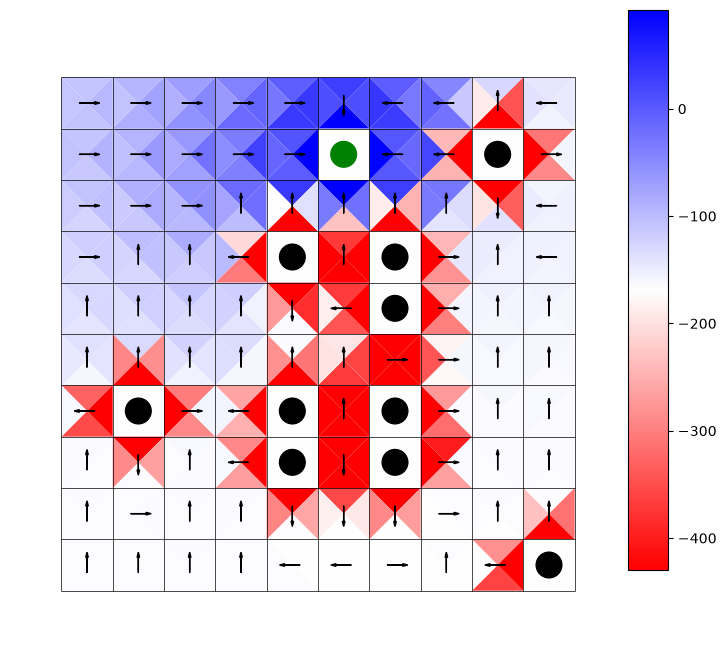

In [120]:
n = 10
goal = (5,8)
obstacles = [(1,3), (9,0), (8,8)] + \
            [(4, 2), (4, 3), (4, 6)] + \
            [(6, 2), (6, 3), (6, 5), (6, 6)]
mdp = build_mdp(n, p=0.8, obstacles=obstacles, goal=goal, gamma=0.8, goal_reward=100, obstacle_reward=-500)

# Perform Q learning with these episodes.
alpha = 0.01
epsilon = 0.7
num_episodes = 50000
Q, policy = q_learning_epsilon_greedy(num_episodes, mdp, mdp.gamma, alpha, epsilon)

# Visualize values:
# 1. Create grid for plotting.
g = MDPGrid(n, n)
axes = g.draw()
# 2. Plot values with colors and numbers.
g.plot_Q(axes, Q, print_numbers=False)
g.plot_policy(axes, policy)
# 3. Draw goal and obstacle cells
g.draw_cell_circle(axes, goal, color='g')
for ob in obstacles:
    g.draw_cell_circle(axes, ob, color='k')   

Now try running the same code block with different values of epsilon: 0 (pure exploitation), 0.1, 0.5, 1.0 (pure exploration). Try also varying num_episodes to get an idea of how many samples the algorithm needs to converge with different epsilon values. Answer the following questions:

1. How does changing the epsilon parameter affect the performance and policy learned by the agent?
2. Can you find a balance (pick a value for epsilon) between exploration and exploitation that leads to both fast convergence and a good policy?

<div class="alert alert-info">
Write your answer in the cell below this one.
</div>

#### How does changing the epsilon parameter affect the performance and policy learned by the agent?

Increasing epsilon allows more exploration, which creates more diffuse gradients in the graph that give information in cells further away from the goal. Decreasing it increases exploitation, which helps converge the Q values for each cell quickly towards the ideal amount. The policy learned is ultimately the same, but exploiting too early results in undefined or incorrect policies far away from the goal.

#### Can you find a balance (pick a value for epsilon) between exploration and exploitation that leads to both fast convergence and a good policy?

Between 0.2 and 0.7 yields good results while providing valid policies for most of the cells in quite a far vicinity away from the goal.

## <a name="problem3"></a> 3. Exploration Functions vs. Epsilon-Greedy [AI-enabled] (10 points)

In Problem 2C, epsilon-greedy Q-learning explored by acting randomly a fixed fraction of the time. In lecture, we discussed an alternate approach, _exploration functions_, which encourage the agent to explore the environment in a more systematic way. This problem *explores* (get it?) the difference between these two approaches.

### <a name="exploration_mdp"></a> 3A. Finding an MDP Where Exploration Functions Win [AI-enabled] (5 points)


Note: like in Problem Set 6, we will use MDPs on graphs, built with `build_graph_mdp(G, goal, p, gamma, goal_reward=100)`. 
<details>
<summary>Click here for a reminder (condensed from Problem Set 6).</summary>
    Each edge of the graph is an action. If the agent plays an action whose edge touches its current state, it moves along that edge to the other endpoint with probability <i>p</i>, and stays in its current state with probability 1-<i>p</i>. Should the agent play an action that corresponds to an edge that is not associated with the current state, then it deterministically stays in the same state. The agent receives a reward of $+100$ when it arrives at the goal state, which is terminal, and *0* for every other transition.
</details>


Recall the exploration function from lecture, which takes a Q-value estimate $u$ and a visit count $n$, and returns an optimistic utility:

$$f(u, n) = u + \frac{k}{n + 1}.$$

(We use $n + 1$ instead of $n$ so that unvisited state-action pairs have a finite bonus of $k$.) Q-learning with an exploration function keeps a count $N(s, a)$ of how many times it has taken action $a$ in state $s$, always acts greedily with respect to $f(Q(s, a), N(s, a))$, and uses the modified Q-update

$$Q(s, a) \leftarrow (1 - \alpha)\, Q(s, a) + \alpha \left[ R(s, a, s') + \gamma \max_{a'} f(Q(s', a'), N(s', a')) \right].$$


Using an LLM (ChatGPT, Claude, etc.) and the `networkx` library, define an MDP and a start state so that Q-learning with the exploration function learns a near-optimal policy for at least 8 of 10 seeds, while epsilon-greedy Q-learning does so for at most 2 of 10 seeds. Some more constraints on the MDP:

- the MDP is built with `build_graph_mdp`, using $p = 0.8$ and $\gamma = 0.95$, on a _tree_ (a connected graph with $|A| = |S| - 1$ edges, like in Problem Set 6) with at most 16 nodes,
- the start state is not the goal state,
- when both agents are trained with $\alpha = 0.1$, $\epsilon = 0.1$, $k = 1$, 500 episodes, and at most 50 steps per episode

Lastly, we say a learned policy $\pi$ is _near-optimal_ if, when evaluated exactly on the true MDP, $V^\pi(\text{start}) \geq 0.9\, V^*(\text{start})$.



The autograder runs its own implementation of epsilon-greedy Q-learning (as in Problem 2B) and Q-learning with the exploration function above. Each implementation differs from Problem 2 in two ways: every episode starts from the same `start` state, instead of a random state, and ties between equally good actions are broken uniformly at random, instead of by the order of `mdp.A`. Each instance of Q-learning is executed with 10 random seeds. 
Running the test cell below prints, for each agent, how many seeds learned a near-optimal policy (defined below), so you can check your MDP before submitting. It also saves a record of every training run to `exploration_traces.pkl`, which you will use for a visualization in 3B.



<div class="alert alert-info">
Implement the function `build_exploration_mdp()`, which returns a tuple `(mdp, start)`, below. Include any LLM-generated code you used to find your MDP.
</div>

In [121]:
def make_path_tree(n_nodes):
    """A path 0-1-...-(n-1) is a tree with n nodes and n-1 edges."""
    return nx.path_graph(n_nodes)

def value_iteration(mdp, tol=1e-10):
    """Exact V* (uses T and R; only for checking, not inside the learners)."""
    V = {s: 0.0 for s in mdp.S}
    while True:
        delta = 0.0
        for s in mdp.S:
            v = max(sum(p * (mdp.R[s][a].get(s2, 0.0) + mdp.gamma * V[s2])
                        for s2, p in mdp.T[s][a].items()) for a in mdp.A)
            delta = max(delta, abs(v - V[s])); V[s] = v
        if delta < tol:
            return V

def policy_evaluation(mdp, policy, tol=1e-10):
    """Exact V^pi on the true MDP."""
    V = {s: 0.0 for s in mdp.S}
    while True:
        delta = 0.0
        for s in mdp.S:
            a = policy[s]
            v = sum(p * (mdp.R[s][a].get(s2, 0.0) + mdp.gamma * V[s2])
                    for s2, p in mdp.T[s][a].items())
            delta = max(delta, abs(v - V[s])); V[s] = v
        if delta < tol:
            return V

def argmax_random_ties(d):
    best = max(d.values())
    return random.choice([a for a, v in d.items() if v == best])

In [122]:
def train_agent(mdp, start, agent, seed, alpha=0.1, epsilon=0.1, k=1,
                num_episodes=500, max_steps=50):
    random.seed(seed)
    Q = {s: {a: 0.0 for a in mdp.A} for s in mdp.S}
    N = {s: {a: 0 for a in mdp.A} for s in mdp.S}
    f = lambda s, a: Q[s][a] + k / (N[s][a] + 1)
    for _ in range(num_episodes):
        s, steps = start, 0
        while not mdp.is_sink_state(s) and steps < max_steps:
            steps += 1
            if agent == "epsilon_greedy":
                a = (random.choice(mdp.A) if random.uniform(0, 1) < epsilon
                     else argmax_random_ties(Q[s]))
            else:
                a = argmax_random_ties({b: f(s, b) for b in mdp.A})
            s2, r = sample_environment(mdp, s, a)
            N[s][a] += 1
            if agent == "epsilon_greedy":
                future = max(Q[s2].values())
            else:
                future = max(f(s2, b) for b in mdp.A)
            Q[s][a] = (1 - alpha) * Q[s][a] + alpha * (r + mdp.gamma * future)
            s = s2
    return {s: argmax_random_ties(Q[s]) for s in mdp.S}

In [123]:
def count_near_optimal(mdp, start, agent, seeds=range(10)):
    v_star = value_iteration(mdp)[start]
    return sum(policy_evaluation(mdp, train_agent(mdp, start, agent, sd))[start]
               >= 0.9 * v_star for sd in seeds)

def search_path_lengths(lengths=range(4, 17)):
    """The search used to pick the MDP: try paths of increasing length."""
    for L in lengths:
        mdp = build_graph_mdp(make_path_tree(L), L - 1, p=0.8, gamma=0.95)
        print(L, "eps-greedy:", count_near_optimal(mdp, 0, "epsilon_greedy"),
                 "explore:", count_near_optimal(mdp, 0, "exploration_function"))

In [124]:
def build_exploration_mdp() -> tuple[MDP, object]:
    """
    Return (mdp, start), where mdp is built with build_graph_mdp(G, goal, p=0.8, gamma=0.95)
    on a tree G with at most 16 nodes, and start is a state of mdp other than the
    goal, such that Q-learning with an exploration function learns a near-optimal policy from
    start for at least 8 of 10 seeds, while epsilon-greedy Q-learning does so for at most 2.
    """
    n_nodes = 16
    G = make_path_tree(n_nodes)
    start, goal = 0, n_nodes - 1
    mdp = build_graph_mdp(G, goal, p=0.8, gamma=0.95)
    return mdp, start

In [125]:
mdp, start = build_exploration_mdp()
print(f"{len(mdp.S)} states, {len(mdp.A)} actions, start = {start}")

16 states, 15 actions, start = 0


In [126]:
Grader.run_single_test_inline(TestPSet7, "test_5_exploration_mdp", locals())

ValueError: no such test method in <class 'principles_of_autonomy.notebook_tests.pset_7.TestPSet7'>: test_5_exploration_mdp

### <a name="exploration_visualization"></a> 3B. Visualize an Explanation for Why Exploration Functions Win [AI-enabled] (5 points)

Using an LLM (ChatGPT, Claude, etc.) and the `matplotlib` library, create a visualization that argues why Q-learning with an exploration function succeeds on your MDP from 3A while epsilon-greedy Q-learning fails. The visualization must articulate an entire argument as to how the structure of your MDP, and the way each agent chooses its actions, leads to the difference.

You do not need to train the agents yourself: running the test in 3A saves a record of every training run to `exploration_traces.pkl`. Load it with:

```python
import pickle
with open("exploration_traces.pkl", "rb") as f:
    traces = pickle.load(f)
```

`traces` is a dictionary with the following keys:
- `"start"`, `"goal"`, and `"V_star_start"`: the start state, the goal state, and $V^*(\text{start})$ for your MDP,
- `"params"`: the hyperparameters used for training ($\alpha$, $\epsilon$, $k$, the number of episodes, and the maximum number of steps per episode),
- `"epsilon_greedy"` and `"exploration_function"`: for each agent, a list with one entry per seed. Each entry is a dictionary with:
    - `"episodes"`: every training episode, as a list of `(state, action, state', reward)` tuples (the same format as `generate_episodes` in Problem 1),
    - `"policy"`: the greedy policy learned at the end of training,
    - `"value_history"`: a list of `(episode, value)` pairs, giving $V^\pi(\text{start})$ of the greedy policy every 10 episodes of training,
    - `"near_optimal"`: whether the final policy is near-optimal.

Some ideas:
- Like the "2D point" example from lecture, show where each agent spends its time: e.g., color the nodes of your graph by how often each agent visited them in `"episodes"`.
- Plot `"value_history"` for each agent, compared with $V^*(\text{start})$.
- Show the episode at which each agent first reaches the goal, across seeds.

<div class="alert alert-info">
Implement the code that plots and displays your visualization in the cell below.
</div>

exploration_traces.pkl not found; training both agents locally (takes ~1 min)...


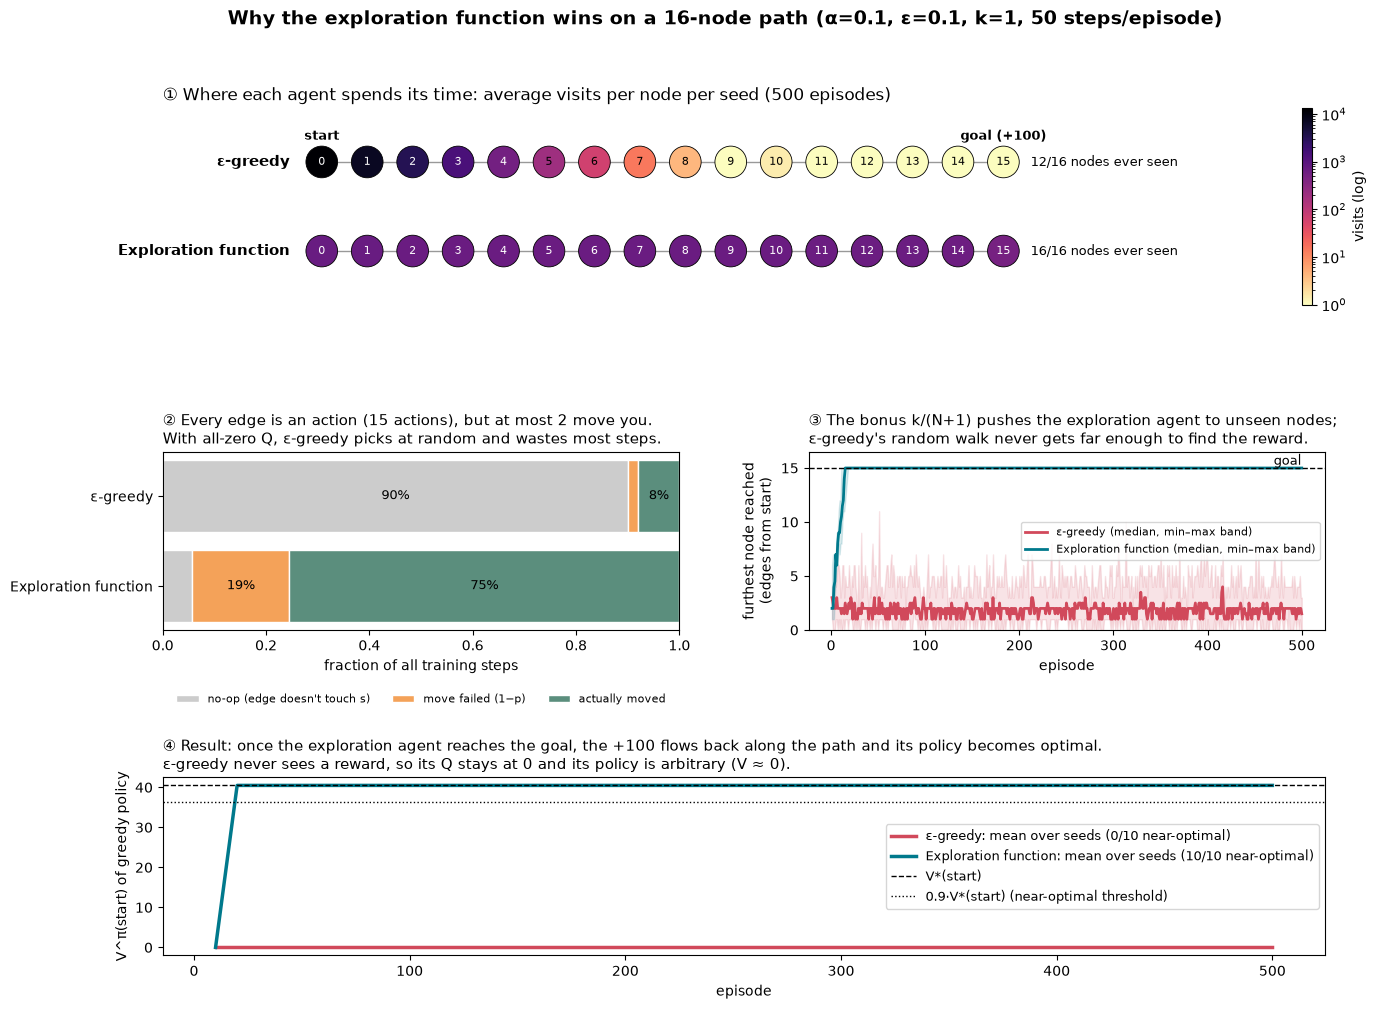

In [127]:
# visualization code here.
import pickle
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import os, random

# ---- If the autograder hasn't produced exploration_traces.pkl locally, generate it ----
# Mirrors the autograder's setup: every episode starts at `start`, ties broken uniformly
# at random, alpha=0.1, epsilon=0.1, k=1, 500 episodes, max 50 steps, seeds 0-9.
def _evaluate_policy(mdp, pi, tol=1e-10):
    V = {s: 0.0 for s in mdp.S}
    while True:
        delta = 0.0
        for s in mdp.S:
            a = pi[s]
            v = sum(p * (mdp.R[s][a].get(s2, 0.0) + mdp.gamma * V[s2]) for s2, p in mdp.T[s][a].items())
            delta = max(delta, abs(v - V[s])); V[s] = v
        if delta < tol:
            return V

def _optimal_values(mdp, tol=1e-10):
    V = {s: 0.0 for s in mdp.S}
    while True:
        delta = 0.0
        for s in mdp.S:
            v = max(sum(p * (mdp.R[s][a].get(s2, 0.0) + mdp.gamma * V[s2]) for s2, p in mdp.T[s][a].items())
                    for a in mdp.A)
            delta = max(delta, abs(v - V[s])); V[s] = v
        if delta < tol:
            return V

def _argmax_random(d):
    best = max(d.values())
    return random.choice([a for a, v in d.items() if v == best])

def _train_with_trace(mdp, start, agent, seed, v_star, alpha, epsilon, k, num_episodes, max_steps):
    random.seed(seed)
    Q = {s: {a: 0.0 for a in mdp.A} for s in mdp.S}
    N = {s: {a: 0 for a in mdp.A} for s in mdp.S}
    f = lambda s, a: Q[s][a] + k / (N[s][a] + 1)
    episodes, value_history = [], []
    for ep_i in range(num_episodes):
        s, steps, ep = start, 0, []
        while not mdp.is_sink_state(s) and steps < max_steps:
            steps += 1
            if agent == "epsilon_greedy":
                a = random.choice(mdp.A) if random.uniform(0, 1) < epsilon else _argmax_random(Q[s])
            else:
                a = _argmax_random({b: f(s, b) for b in mdp.A})
            s2, r = sample_environment(mdp, s, a)
            N[s][a] += 1
            future = max(Q[s2].values()) if agent == "epsilon_greedy" else max(f(s2, b) for b in mdp.A)
            Q[s][a] = (1 - alpha) * Q[s][a] + alpha * (r + mdp.gamma * future)
            ep.append((s, a, s2, r)); s = s2
        episodes.append(ep)
        if (ep_i + 1) % 10 == 0:
            greedy = {x: max(Q[x], key=Q[x].get) for x in mdp.S}
            value_history.append((ep_i + 1, _evaluate_policy(mdp, greedy)[start]))
    policy = {x: _argmax_random(Q[x]) for x in mdp.S}
    return {"episodes": episodes, "policy": policy, "value_history": value_history,
            "near_optimal": _evaluate_policy(mdp, policy)[start] >= 0.9 * v_star}

if not os.path.exists("exploration_traces.pkl"):
    print("exploration_traces.pkl not found; training both agents locally (takes ~1 min)...")
    _mdp, _start = build_exploration_mdp()
    _goal = next(s for s in _mdp.S if _mdp.is_sink_state(s))
    _params = {"alpha": 0.1, "epsilon": 0.1, "k": 1, "num_episodes": 500, "max_steps": 50}
    _v_star = _optimal_values(_mdp)[_start]
    _traces = {"start": _start, "goal": _goal, "V_star_start": _v_star, "params": _params}
    for _agent in ("epsilon_greedy", "exploration_function"):
        _traces[_agent] = [_train_with_trace(_mdp, _start, _agent, seed, _v_star, **_params)
                           for seed in range(10)]
    with open("exploration_traces.pkl", "wb") as f:
        pickle.dump(_traces, f)

# ---- Visualization ----
with open("exploration_traces.pkl", "rb") as f:
    traces = pickle.load(f)

start, goal, v_star = traces["start"], traces["goal"], traces["V_star_start"]
params = traces["params"]
AGENTS = [("epsilon_greedy", "ε-greedy", "#d1495b"),
          ("exploration_function", "Exploration function", "#00798c")]

# Rebuild the tree from the actions (every action is an edge).
edges = {a for agent, _, _ in AGENTS for run in traces[agent]
         for ep in run["episodes"] for (_, a, _, _) in ep}
G = nx.Graph(list(edges))
dist = nx.single_source_shortest_path_length(G, start)
goal_dist = dist[goal]
n_actions = G.number_of_edges()

def visit_counts(runs):
    """Average number of times each node is occupied per seed."""
    c = {s: 0 for s in G.nodes}
    for run in runs:
        for ep in run["episodes"]:
            for (s, _, _, _) in ep:
                c[s] += 1
            if ep:
                c[ep[-1][2]] += 1
    return {s: v / len(runs) for s, v in c.items()}

def furthest_per_episode(runs):
    """For each seed and episode, the furthest node (in edges from start) reached."""
    return np.array([[max([dist[s2] for (_, _, s2, _) in ep] + [0]) for ep in run["episodes"]]
                     for run in runs])

def step_breakdown(runs):
    """Fraction of steps that were no-ops (edge not touching s), failed moves, or real moves."""
    noop = fail = move = 0
    for run in runs:
        for ep in run["episodes"]:
            for (s, a, s2, _) in ep:
                if s not in a:
                    noop += 1
                elif s2 == s:
                    fail += 1
                else:
                    move += 1
    tot = noop + fail + move
    return noop / tot, fail / tot, move / tot

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[1.1, 1, 1], hspace=0.8, wspace=0.25)

# ---- Panel 1: where each agent spends its time, drawn on the tree itself ----
counts = {k: visit_counts(traces[k]) for k, _, _ in AGENTS}
vmax = max(max(c.values()) for c in counts.values())
norm = LogNorm(vmin=1, vmax=vmax)
pos = {s: (dist[s], 0) for s in G.nodes} if max(dict(G.degree).values()) <= 2 \
      else nx.kamada_kawai_layout(G)
ax1 = fig.add_subplot(gs[0, :])
ax1.set_title("① Where each agent spends its time: average visits per node per seed "
              f"({params['num_episodes']} episodes)", loc="left", fontsize=12)
for row, (key, label, _) in enumerate(AGENTS):
    y = -row * 1.0
    p = {s: (x, y + yy) for s, (x, yy) in pos.items()}
    vals = [max(counts[key][s], 1) for s in G.nodes]
    nx.draw_networkx_edges(G, p, ax=ax1, edge_color="#999")
    sc = nx.draw_networkx_nodes(G, p, ax=ax1, node_color=vals, cmap="magma_r", vmin=1, vmax=vmax,
                                node_size=520, edgecolors="black", linewidths=0.6)
    sc.set_norm(norm)
    for s_ in G.nodes:
        ax1.text(*p[s_], str(s_), ha="center", va="center", fontsize=8,
                 color="white" if norm(max(counts[key][s_], 1)) > 0.6 else "black")
    ax1.text(min(x for x, _ in p.values()) - 0.7, y, label, ha="right", va="center",
             fontsize=11, fontweight="bold")
    reached = sum(counts[key][s] > 0 for s in G.nodes)
    ax1.text(max(x for x, _ in p.values()) + 0.6, y, f"{reached}/{G.number_of_nodes()} nodes ever seen",
             ha="left", va="center", fontsize=9)
for s, tag in [(start, "start"), (goal, "goal (+100)")]:
    ax1.annotate(tag, xy=(pos[s][0], 0.25), ha="center", fontsize=9, fontweight="bold")
cb = fig.colorbar(sc, ax=ax1, fraction=0.02, pad=0.12)
cb.set_label("visits (log)")
ax1.set_xlim(-3.5, max(x for x, _ in pos.values()) + 3.5)
ax1.set_ylim(-1.6, 0.6)
ax1.axis("off")

# ---- Panel 2: why ε-greedy stalls: most actions do nothing ----
ax2 = fig.add_subplot(gs[1, 0])
labels_bd = ["no-op (edge doesn't touch s)", "move failed (1−p)", "actually moved"]
colors_bd = ["#cccccc", "#f4a259", "#5b8e7d"]
for i, (key, label, _) in enumerate(AGENTS):
    left = 0
    for frac, lab, col in zip(step_breakdown(traces[key]), labels_bd, colors_bd):
        ax2.barh(i, frac, left=left, color=col, edgecolor="white", label=lab if i == 0 else None)
        if frac > 0.06:
            ax2.text(left + frac / 2, i, f"{frac:.0%}", ha="center", va="center", fontsize=9)
        left += frac
ax2.set_yticks(range(len(AGENTS)), [l for _, l, _ in AGENTS])
ax2.set_xlim(0, 1); ax2.invert_yaxis()
ax2.set_xlabel("fraction of all training steps")
ax2.set_title(f"② Every edge is an action ({n_actions} actions), but at most 2 move you.\n"
              "With all-zero Q, ε-greedy picks at random and wastes most steps.",
              loc="left", fontsize=11)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=8, frameon=False)

# ---- Panel 3: how far from start each agent gets ----
ax3 = fig.add_subplot(gs[1, 1])
for key, label, col in AGENTS:
    far = furthest_per_episode(traces[key])
    x = np.arange(1, far.shape[1] + 1)
    ax3.fill_between(x, far.min(0), far.max(0), color=col, alpha=0.15)
    ax3.plot(x, np.median(far, 0), color=col, lw=2, label=f"{label} (median, min–max band)")
ax3.axhline(goal_dist, ls="--", color="black", lw=1)
ax3.text(params["num_episodes"], goal_dist + 0.3, "goal", ha="right", fontsize=9)
ax3.set_xlabel("episode"); ax3.set_ylabel("furthest node reached\n(edges from start)")
ax3.set_ylim(0, goal_dist + 1.5)
ax3.set_title("③ The bonus k/(N+1) pushes the exploration agent to unseen nodes;\n"
              "ε-greedy's random walk never gets far enough to find the reward.",
              loc="left", fontsize=11)
ax3.legend(fontsize=8, loc="center right")

# ---- Panel 4: the outcome ----
ax4 = fig.add_subplot(gs[2, :])
for key, label, col in AGENTS:
    runs = traces[key]
    for run in runs:
        e, v = zip(*run["value_history"])
        ax4.plot(e, v, color=col, alpha=0.25, lw=1)
    mean = np.mean([[v for _, v in run["value_history"]] for run in runs], 0)
    n_ok = sum(run["near_optimal"] for run in runs)
    ax4.plot(e, mean, color=col, lw=2.5, label=f"{label}: mean over seeds ({n_ok}/{len(runs)} near-optimal)")
ax4.axhline(v_star, color="black", ls="--", lw=1, label="V*(start)")
ax4.axhline(0.9 * v_star, color="black", ls=":", lw=1, label="0.9·V*(start) (near-optimal threshold)")
ax4.set_xlabel("episode"); ax4.set_ylabel("V^π(start) of greedy policy")
ax4.set_title("④ Result: once the exploration agent reaches the goal, the +100 flows back along the path "
              "and its policy becomes optimal.\nε-greedy never sees a reward, so its Q stays at 0 "
              "and its policy is arbitrary (V ≈ 0).", loc="left", fontsize=11)
ax4.legend(fontsize=9, loc="center right")

fig.suptitle(f"Why the exploration function wins on a {G.number_of_nodes()}-node path "
             f"(α={params['alpha']}, ε={params['epsilon']}, k={params['k']}, "
             f"{params['max_steps']} steps/episode)", fontsize=14, fontweight="bold", y=0.97)
plt.show()

## <a name="part4"></a> 4. Time Spent on Pset (5 points)

Please use [this form](https://forms.gle/pbng9KntwM5V6Fr46) to tell us how long you spent on this pset. After you submit the form, the form will give you a confirmation word. Please enter that confirmation word below to get an extra 5 points. 

In [128]:
form_confirmation_word = "TARS"

In [129]:
# Run all tests
Grader.grade_output([TestPSet7], [locals()], "results.json")
Grader.print_test_results("results.json")

Test passed!!

Test passed!!

Test passed!!

Test passed!!

Total score is 70/75.

Score for test_1_direct_evaluation (principles_of_autonomy.notebook_tests.pset_7.TestPSet7.test_1_direct_evaluation) is 20/20.

Score for test_2_TD_learning (principles_of_autonomy.notebook_tests.pset_7.TestPSet7.test_2_TD_learning) is 20/20.

Score for test_3_Q_learning (principles_of_autonomy.notebook_tests.pset_7.TestPSet7.test_3_Q_learning) is 20/20.

Score for test_4_Q_learning (principles_of_autonomy.notebook_tests.pset_7.TestPSet7.test_4_Q_learning) is 10/10.

Score for test_5_form_word (principles_of_autonomy.notebook_tests.pset_7.TestPSet7.test_5_form_word) is 0/5.
- Test Failed: Incorrect form word TARS



In [130]:
###############################################
#   SAVE YOUR NOTEBOOK BEFORE SUBMITTING!!!   #
###############################################

In [131]:
# Make sure you save the notebook before running this cell so that the most updated version is zipped!
Grader.prepare_submission("ProblemSet07_RL_release")

Open-ended responses written to ProblemSet07_RL_release_responses_only.ipynb
Compressed files in folder to ../ps7/ps7.zip (submit this to Gradescope)


/Users/shiham/Desktop/padm_local_f26/homeworks/ps7/.venv/lib/python3.14/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
